In [1]:
import osmnx as ox
import networkx as nx
import r5py as r
from matplotlib import pyplot as plt

import pandas as pd
import geopandas as gpd
import shapely

pd.set_option("display.max_columns", None)

descargar el polígono del area de interés

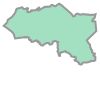

In [ ]:
# place_name = "Provincia de Concepción, Chile"
place_name = "Concepción, Chile"

# geocode_to_gdf descarga el gdf con geometría en lon, lat (EPGS:4326)
area_gdf = ox.geocode_to_gdf(place_name)

area = area_gdf.geometry.iloc[0]
area

descargar el pbf de chile y guardarlo en network/ con el siguiente comando
```bash
cd network
wget https://download.geofabrik.de/south-america/chile-latest.osm.pbf
```

In [60]:
nodes_clipped.lon = nodes_clipped.geometry.x
nodes_clipped.lat = nodes_clipped.geometry.y
nodes_clipped

,lon,lat,tags,visible,version,timestamp,changeset,id,geometry
0,675656.019804,5.923889e+06,None,True,76,1742331558,0,267548301,POINT (675656.02 5923889.386)
1,675661.725303,5.923895e+06,"{'crossing': 'traffic_signals', 'highway': 'cr...",True,2,1742331558,0,11115686725,POINT (675661.725 5923895.152)
2,675669.776668,5.923906e+06,None,True,1,1742331558,0,12677463345,POINT (675669.777 5923905.619)
3,675704.321132,5.923951e+06,None,True,7,1742331558,0,5695201203,POINT (675704.321 5923950.548)
4,689889.237307,5.918347e+06,None,True,4,1494823303,0,303482252,POINT (689889.237 5918346.84)
...,...,...,...,...,...,...,...,...,...
40024,674077.434172,5.925864e+06,None,True,1,1651193996,0,9701904423,POINT (674077.434 5925864.241)
40025,674077.353440,5.925860e+06,None,True,1,1651193996,0,9701904430,POINT (674077.353 5925859.847)
40026,674077.309570,5.926156e+06,None,True,1,1651632146,0,9712830264,POINT (674077.31 5926155.614)
40027,674063.593524,5.926154e+06,None,True,1,1651632146,0,9712830263,POINT (674063.594 5926154.073)


In [61]:
G = osm.to_graph(nodes_clipped, edges_clipped, graph_type="networkx", simplify=True)


In [ ]:
import pyrosm

# ruta de tu archivo local de Chile descargado
fp = "network/chile-latest.osm.pbf"

# pyrosm acepta tu polígono (4326) directamente para filtrar el PBF de forma eficiente
osm = pyrosm.OSM(fp, bounding_box=area)

# extraer la red de conducción (driving) junto con sus nodos
nodes, edges = osm.get_network(network_type="driving", nodes=True)

# realizar un recorte (clip) geométrico exacto con tu polígono 
# para eliminar cualquier tramo que sobresalga del límite provincial

# proyectar a UTM (32718)
nodes_utm = nodes.to_crs(32718)
edges_utm = edges.to_crs(32718)
area_utm = area_gdf.to_crs(32718).iloc[0].geometry

# cortar usando el spatial index de geopandas
match_indices = edges_utm.sindex.query(area_utm, predicate="intersects")
edges_clipped = edges_utm.iloc[match_indices]

# filtrar únicamente los nodos que pertenecen a las aristas recortadas
node_ids = set(edges_clipped['u']).union(set(edges_clipped['v']))
nodes_clipped = nodes_utm[nodes_utm['id'].isin(node_ids)]

# convertirlo a un grafo G de networkx
G = osm.to_graph(nodes_clipped, edges_clipped, graph_type="networkx", simplify=True)

print(f"done\n{len(G.nodes):,} nodes\n{len(G.edges):,} edges")

done
5,809 nodes
13,220 edges


In [ ]:
# guardar grafo
ox.save_graph_geopackage(G, "network/concepción.gpkg", encoding="latin-1")

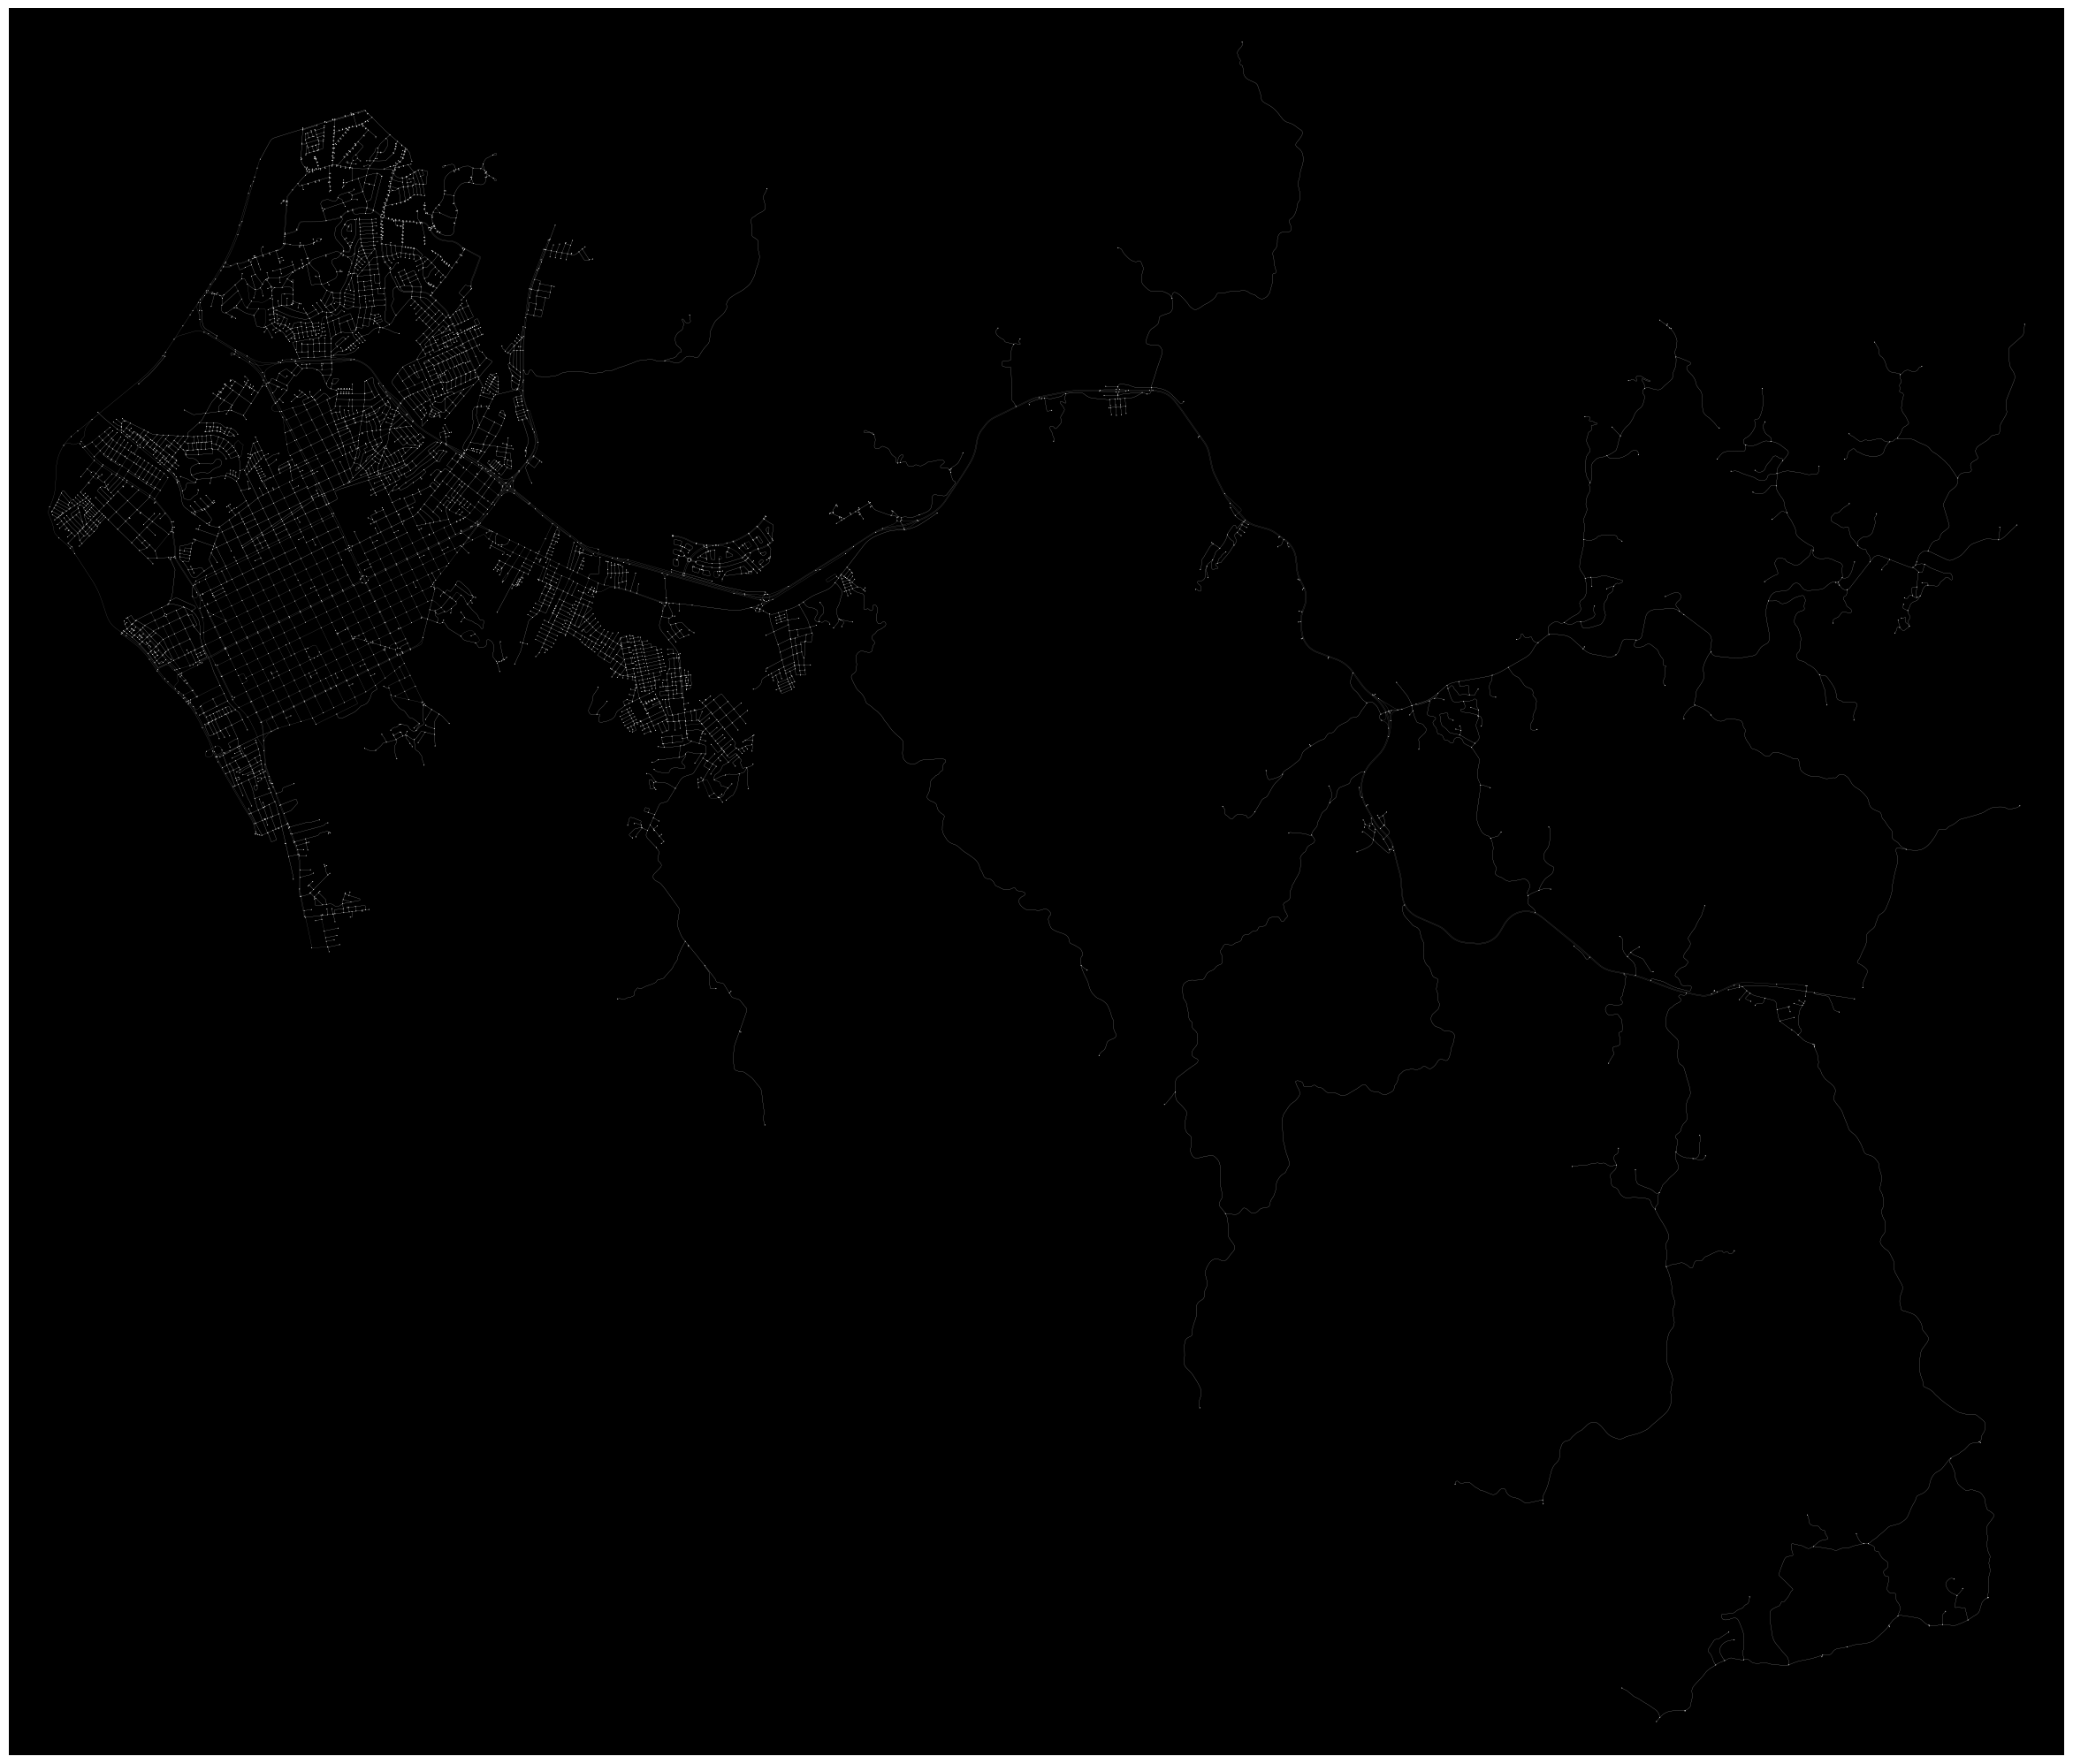

(<Figure size 3000x3000 with 1 Axes>,
 <Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>)

In [69]:
# dibujar grafo
ox.plot_graph(G, figsize=(30,30), edge_linewidth=0.1, node_size=0.5, node_color="white", bgcolor="black")

In [96]:
# reobtener los gdf edges y nodes del grafo simplificado
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

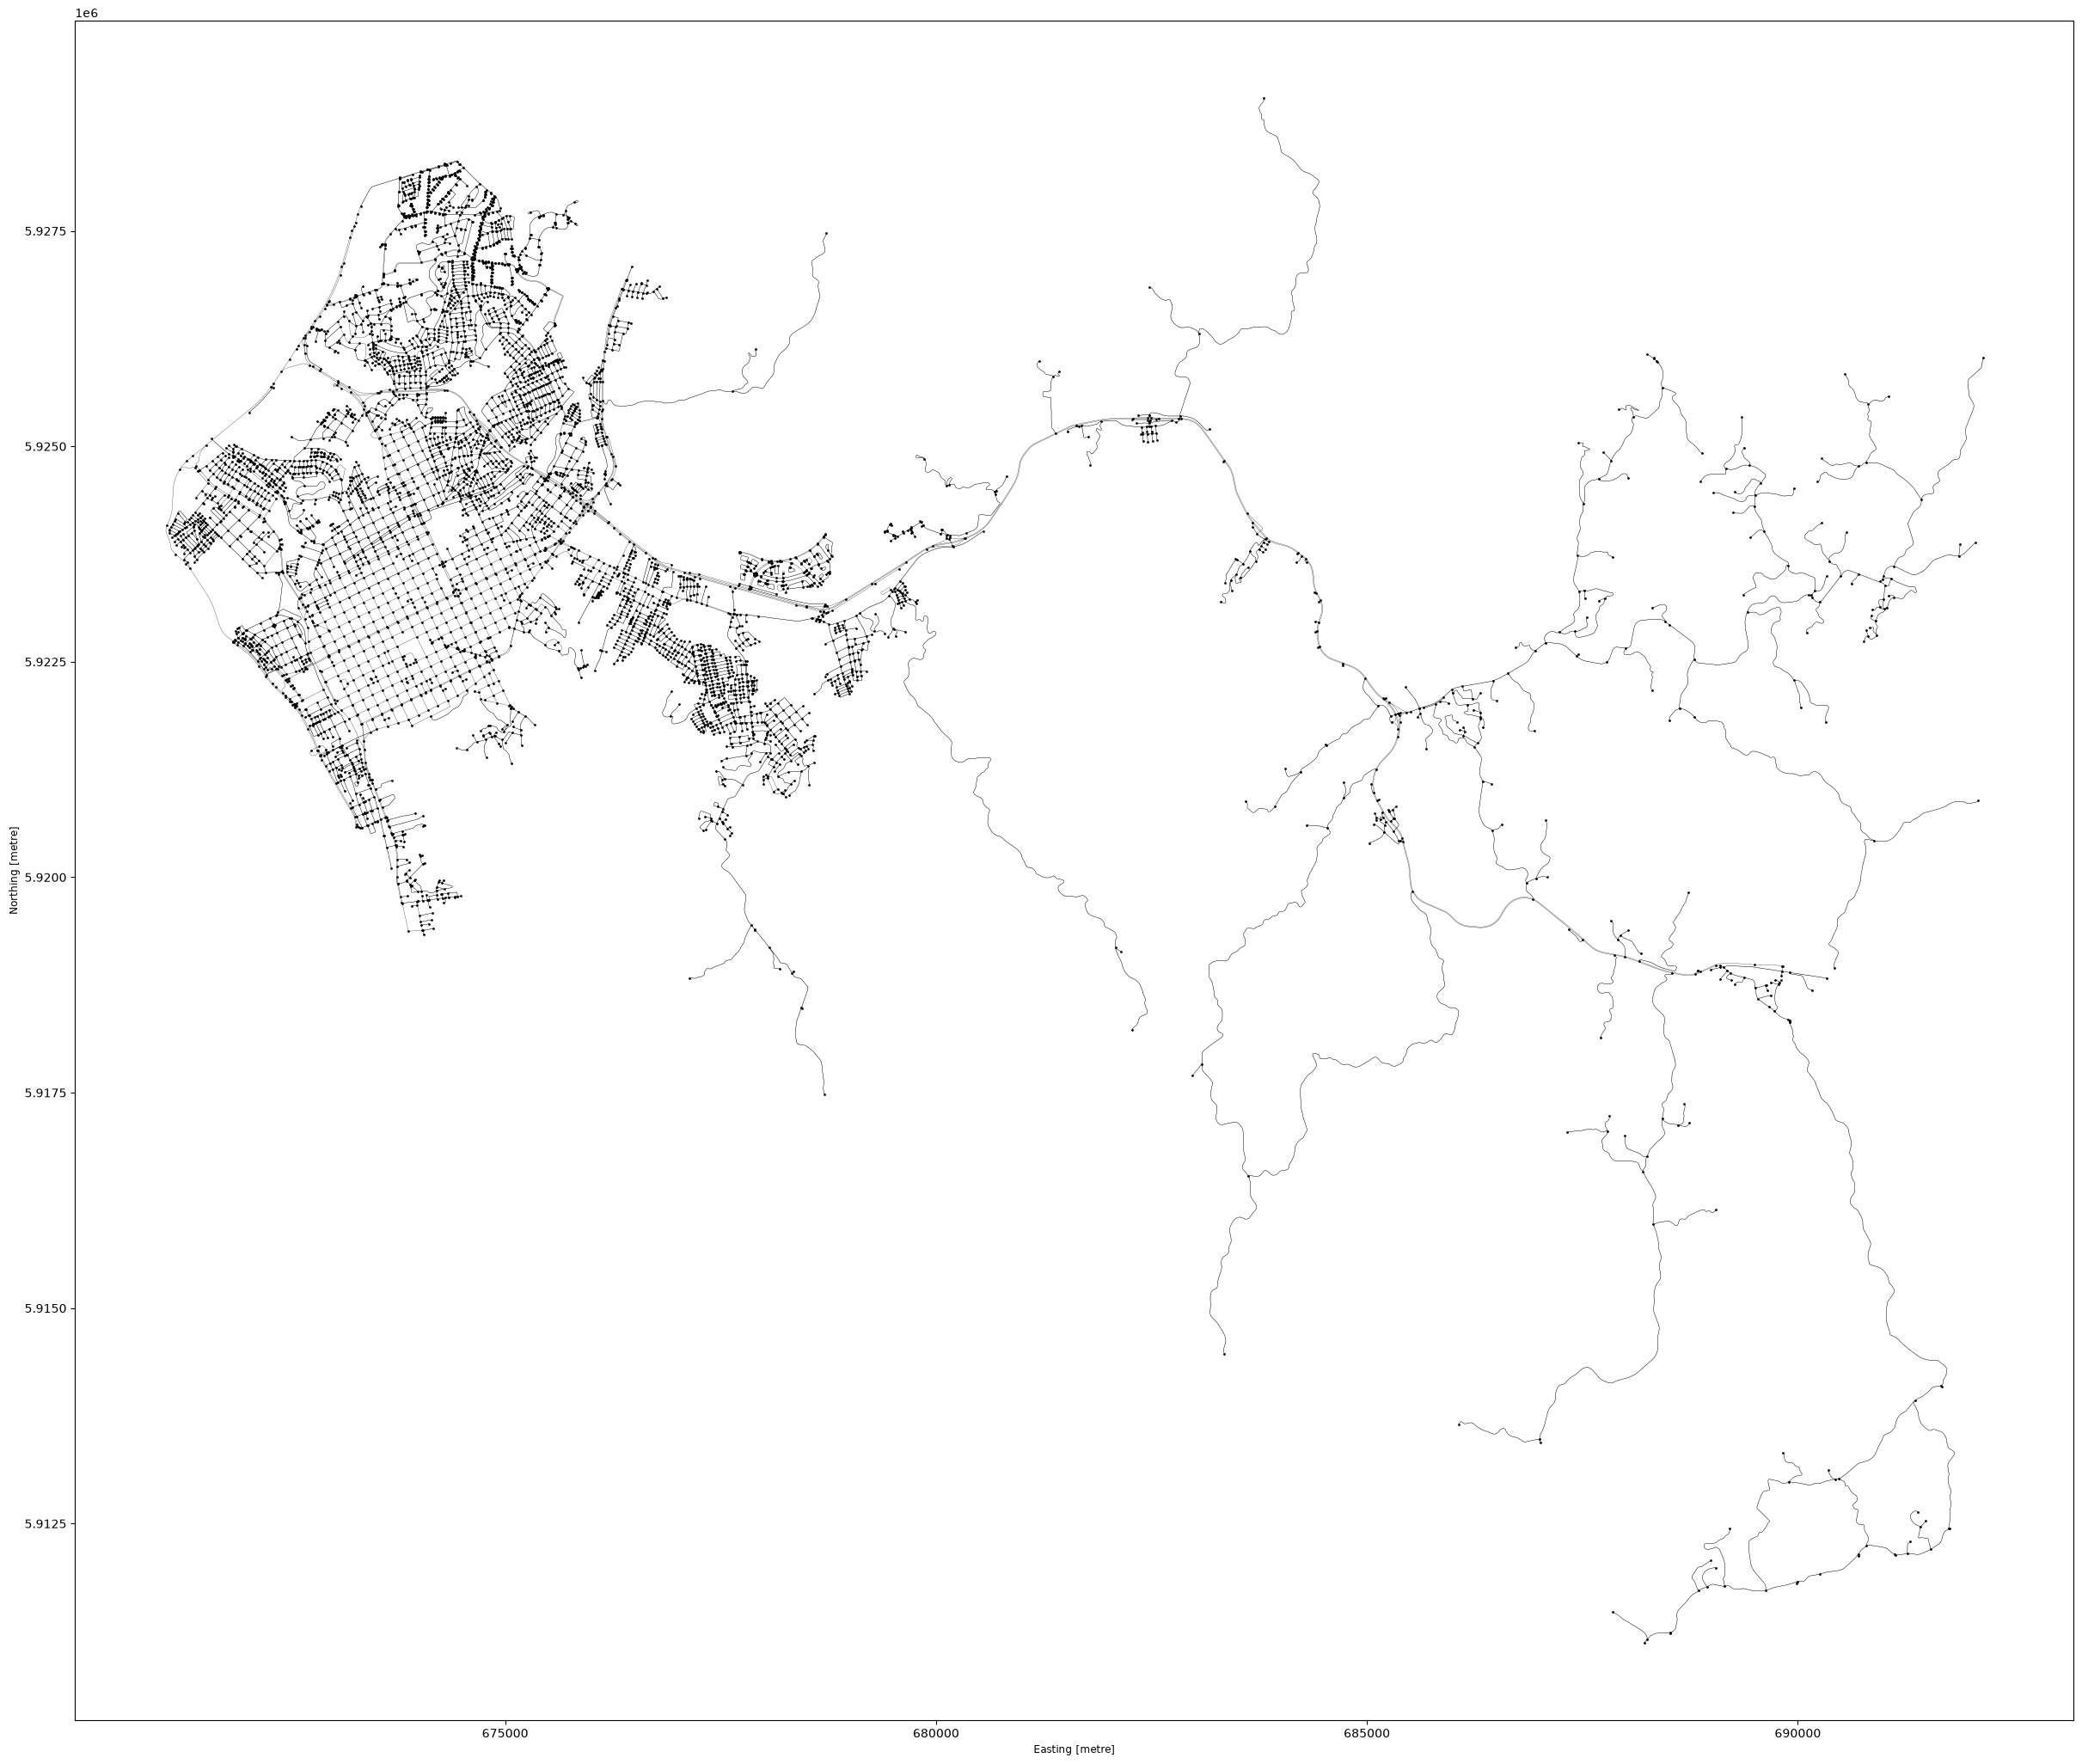

In [97]:
# dibujar los gdf independientemente
ax = edges_gdf.plot(figsize=(30,30), linewidth=0.2, color="black", legend=True)
nodes_gdf.plot(ax=ax, markersize=1, color="black")